# Milestone 3 — CNNs for image quality assessment
**Muhammad Ammar Sohail · Mohamed Kamaleldin | ICS 471**

We predict **Mean Opinion Score (MOS)**, an aggregate of human image-quality ratings,
on the released 0–100 scale. We compare an eight-convolution CNN trained from scratch,
three pretrained CNNs, and an SVR using features from the best transfer model.

We retain the exact Milestone 2 split: **6,446 training / 1,612 validation / 2,015 test**.
Augmentation is used only for training. Validation SROCC (Spearman rank correlation) selects settings and checkpoints;
MAE and RMSE are reported in MOS units. Because this is regression, these metrics replace
classification accuracy. Test evaluation is deferred to the final section.

All implementation code is included in this notebook; no repository modules are needed.

## Setup
On Colab, select an A100 GPU. The next cells download the public dataset directly into
the runtime when it is absent. A local run reuses the existing project data directory.
Checkpoints and per-epoch logs are saved as each experiment completes.

In [1]:
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "Pillow",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
}
missing = [
    package for module, package in packages.items() if importlib.util.find_spec(module) is None
]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from pathlib import Path
import gc
import os
import hashlib
import json
import platform
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn
from torchvision import transforms
from PIL import Image, ImageOps
from IPython.display import display

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
)
IN_COLAB = Path("/content").exists()
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/mlp_data.py").exists()), Path.cwd()
)
DATA_DIR = Path("/content/koniq") if IN_COLAB else ROOT / "data/koniq/images/KonIQ-10k"
OUTPUT = Path("/content/milestone3") if IN_COLAB else ROOT / "outputs/milestone3"
OUTPUT.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 64
WORKERS = min(8, os.cpu_count() or 2) if IN_COLAB else 0
TUNING_EPOCHS = 15
FINAL_EPOCHS = 30
TRANSFER_EPOCHS = 15
SEED = 42
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
    torch.set_float32_matmul_precision("high")
print("Data:", DATA_DIR)
print("Results:", OUTPUT)
versions = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print("Versions:", versions)
(OUTPUT / "versions.json").write_text(json.dumps(versions, indent=2))


Device: cuda
GPU: NVIDIA A100-SXM4-80GB
GPU memory (GB): 85.1
Data: /content/koniq
Results: /content/milestone3
Versions: {'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'numpy': '2.4.6', 'pandas': '2.2.3'}


126

## 1. Data and preprocessing
Images remain spatial tensors rather than flattened MLP inputs. The scratch model uses
**192×256 RGB tensors** and training-only channel normalization. MOS is standardized using
training statistics. Pretrained models use their ImageNet normalization and deterministic
weight-specific evaluation transforms (224×224 for VGG19/ResNet50; 299×299 for InceptionV3).

The split code below is the same seeded split used in M2: retain the official test set,
then split the remaining image indices 80/20 with seed 42. Only image pixels are inputs.

In [2]:
"""Image loading, M2 split preservation, and training-only augmentation."""

import hashlib
import random
import shutil
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

METADATA_URL = (
    "https://raw.githubusercontent.com/subpic/koniq/master/metadata/koniq10k_distributions_sets.csv"
)
ARCHIVE_URL = "https://zenodo.org/api/records/19500652/files/KonIQ-10k.zip/content"


def prepare_dataset(data_dir):
    """Reuse local data, or download the public archive directly on Colab."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    metadata_path = data_dir / "koniq10k_distributions_sets.csv"
    if not metadata_path.exists():
        print("Downloading MOS metadata...")
        urllib.request.urlretrieve(METADATA_URL, metadata_path)
    frame = pd.read_csv(metadata_path)
    image_paths = {p.name: p for p in data_dir.rglob("*.jpg")}
    if not set(frame.image_name).issubset(image_paths):
        archive = data_dir / "KonIQ-10k.zip"
        if not archive.exists():
            print("Downloading the 768 MB image archive; this may take a few minutes...")
            partial = archive.with_suffix(".zip.part")
            offset = partial.stat().st_size if partial.exists() else 0
            request = urllib.request.Request(ARCHIVE_URL, headers={"Range": f"bytes={offset}-"})
            with urllib.request.urlopen(request) as response:
                with partial.open("ab" if response.status == 206 else "wb") as destination:
                    shutil.copyfileobj(response, destination)
            partial.rename(archive)
        with archive.open("rb") as stream:
            checksum = hashlib.file_digest(stream, "md5").hexdigest()
        if checksum != "ca88afc3569f4962f10b4efe45aa9ed7":
            raise ValueError("Image archive checksum differs from the published archive")
        with zipfile.ZipFile(archive) as images:
            images.extractall(data_dir)
        image_paths = {p.name: p for p in data_dir.rglob("*.jpg")}
    missing = set(frame.image_name) - image_paths.keys()
    if missing:
        raise FileNotFoundError(f"Missing {len(missing)} labeled images")
    frame["path"] = frame.image_name.map(image_paths)
    return frame


def milestone2_split(frame):
    """Exactly the same official-test + seeded development split as M2."""
    development = np.flatnonzero(frame["set"].to_numpy() != "test")
    test = np.flatnonzero(frame["set"].to_numpy() == "test")
    # Preserve the official test set and the exact seeded M2 development split.
    train, validation = train_test_split(development, test_size=0.2, random_state=42)
    return {
        "training": frame.iloc[np.sort(train)].reset_index(drop=True),
        "validation": frame.iloc[np.sort(validation)].reset_index(drop=True),
        "test": frame.iloc[test].reset_index(drop=True),
    }


class ImageQualityDataset(Dataset):
    def __init__(self, frame, transform, target_mean, target_std):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
        self.target_mean = target_mean
        self.target_std = target_std

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            pixels = self.transform(image)
        target = torch.tensor([(row.MOS - self.target_mean) / self.target_std], dtype=torch.float32)
        return pixels, target


def training_statistics(train_frame, size=(192, 256)):
    transform = transforms.Compose([transforms.Resize(size), transforms.ToTensor()])
    dataset = ImageQualityDataset(train_frame, transform, 0.0, 1.0)
    loader = DataLoader(dataset, batch_size=64, num_workers=0)
    total, squared, pixels = (
        torch.zeros(3, dtype=torch.float64),
        torch.zeros(3, dtype=torch.float64),
        0,
    )
    for images, _ in loader:
        images = images.double()
        total += images.sum((0, 2, 3))
        squared += images.square().sum((0, 2, 3))
        pixels += images.shape[0] * images.shape[2] * images.shape[3]
    # Accumulate only training pixels; validation and test never fit normalization.
    mean = total / pixels
    std = (squared / pixels - mean.square()).clamp_min(1e-12).sqrt()
    return mean.float().tolist(), std.float().tolist()


def image_transforms(model_name, training, channel_mean=None, channel_std=None):
    if model_name == "scratch":
        size = (192, 256)
        mean, std = channel_mean, channel_std
    else:
        weights = {
            "vgg19": models.VGG19_Weights.DEFAULT,
            "resnet50": models.ResNet50_Weights.DEFAULT,
            "inception_v3": models.Inception_V3_Weights.DEFAULT,
        }[model_name]
        preset = weights.transforms()
        mean, std = preset.mean, preset.std
        if not training:
            return preset
        size = (preset.crop_size[0], preset.crop_size[0])
    if training:
        # 80–100% AREA retained, with the source photograph's 4:3 aspect ratio.
        return transforms.Compose(
            [
                transforms.RandomResizedCrop(size, scale=(0.8, 1.0), ratio=(4 / 3, 4 / 3)),
                transforms.RandomHorizontalFlip(0.5),
                transforms.ToTensor(),
                transforms.Normalize(mean, std),
            ]
        )
    return transforms.Compose(
        [transforms.Resize(size), transforms.ToTensor(), transforms.Normalize(mean, std)]
    )


def make_loaders(
    splits,
    model_name,
    channel_mean,
    channel_std,
    target_mean,
    target_std,
    batch_size=64,
    workers=2,
    seed=42,
):
    train_transform = image_transforms(model_name, True, channel_mean, channel_std)
    eval_transform = image_transforms(model_name, False, channel_mean, channel_std)
    frames = {
        "training": splits["training"],
        "train_eval": splits["training"],
        "validation": splits["validation"],
        "test": splits["test"],
    }
    loaders = {}
    for name, frame in frames.items():
        dataset = ImageQualityDataset(
            frame,
            train_transform if name == "training" else eval_transform,
            target_mean,
            target_std,
        )
        loaders[name] = DataLoader(
            dataset,
            batch_size=batch_size,
            shuffle=name == "training",
            num_workers=workers,
            pin_memory=torch.cuda.is_available(),
            generator=torch.Generator().manual_seed(seed),
            persistent_workers=workers > 0,
        )
    return loaders


In [3]:
metadata = prepare_dataset(DATA_DIR)
splits = milestone2_split(metadata)
summary = pd.DataFrame(
    [
        {"split": name, "images": len(frame), "mean_MOS": frame.MOS.mean()}
        for name, frame in splits.items()
    ]
)
display(summary)
assert [len(splits[name]) for name in ["training", "validation", "test"]] == [6446, 1612, 2015]
manifest = pd.concat(
    [frame[["image_name", "MOS"]].assign(split=name) for name, frame in splits.items()]
)
manifest.to_csv(OUTPUT / "split_manifest.csv", index=False)
split_fingerprint = hashlib.sha256(
    manifest[["image_name", "split"]].to_csv(index=False).encode()
).hexdigest()
assert (
    split_fingerprint == "15876657831ae2343cbce459bdf90c158e325499922b3eb557e36d60f180d238"
), "Image assignments differ from M2"
print("Exact M2 split verified:", split_fingerprint)
target_mean = float(splits["training"].MOS.mean())
target_std = float(splits["training"].MOS.std(ddof=0))
print("Computing channel statistics from unaugmented training images...")
channel_mean, channel_std = training_statistics(splits["training"])
print("RGB mean:", channel_mean, "RGB std:", channel_std)
print("Training MOS mean/std:", target_mean, target_std)


,split,images,mean_MOS
0,training,6446,58.594748
1,validation,1612,59.305483
2,test,2015,58.700369


Exact M2 split verified: 15876657831ae2343cbce459bdf90c158e325499922b3eb557e36d60f180d238
Computing channel statistics from unaugmented training images...
RGB mean: [0.4633491039276123, 0.41926732659339905, 0.37213683128356934] RGB std: [0.32763323187828064, 0.31701672077178955, 0.32753515243530273]
Training MOS mean/std: 58.594748138959126 15.533188025334578


## 2. Training augmentation
Every training image passes through **random cropping and horizontal flipping** when loaded.
The crop retains 80–100% of the original area with the original 4:3 aspect ratio: at most
20% of the total area is removed, not 20% from every edge. Validation/test images are never
randomly augmented. The five examples below span training MOS values.

Flipping preserves image defects; mild cropping is assumed to preserve the global score
approximately. A crop can remove a localized defect, so this introduces some label noise.
We avoid added noise, blur, strong color changes, CutMix, and cutout because they can change
perceived quality without a known replacement MOS.

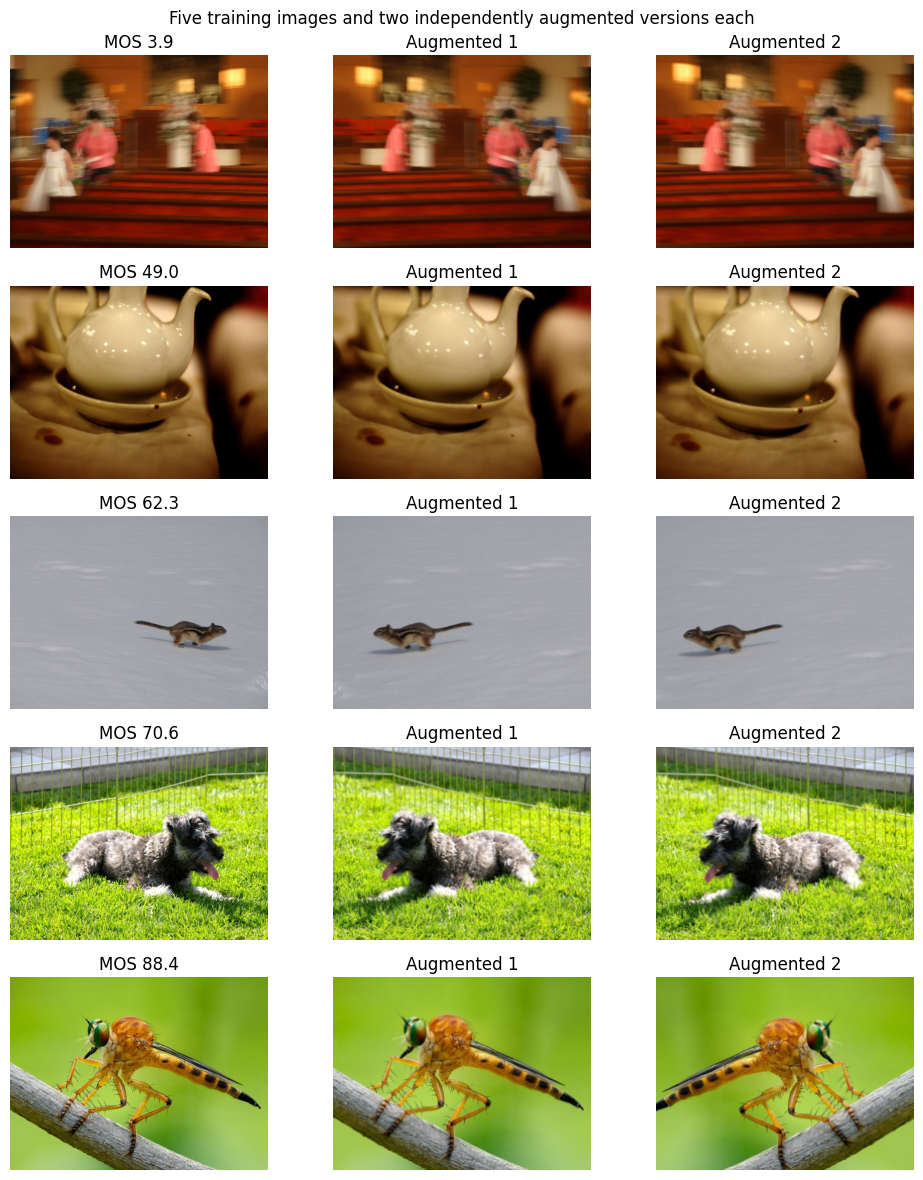

In [4]:
preview_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop((192, 256), scale=(0.8, 1.0), ratio=(4 / 3, 4 / 3)),
        transforms.RandomHorizontalFlip(0.5),
    ]
)
examples = (
    splits["training"]
    .sort_values("MOS")
    .iloc[np.linspace(0, len(splits["training"]) - 1, 5).astype(int)]
)
torch.manual_seed(SEED)
fig, axes = plt.subplots(5, 3, figsize=(10, 12))
for row_index, row in enumerate(examples.itertuples()):
    with Image.open(row.path) as source:
        original = ImageOps.exif_transpose(source).convert("RGB")
    for column, image in enumerate(
        [original, preview_transform(original), preview_transform(original)]
    ):
        axes[row_index, column].imshow(image)
        axes[row_index, column].axis("off")
        axes[row_index, column].set_title(
            f"MOS {row.MOS:.1f}" if column == 0 else f"Augmented {column}"
        )
fig.suptitle("Five training images and two independently augmented versions each")
fig.tight_layout()
fig.savefig(OUTPUT / "augmentation_examples.png", dpi=160)
plt.show()


## 3. Custom CNN architecture
Eight convolutions exploit local quality cues. **Every convolution is followed by BatchNorm
and ReLU**, including the 1×1 channel-compression layer in block 4. Max pooling downsamples
after each block. Global average pooling limits head size; a linear scalar output predicts
standardized MOS. Dropout and AdamW weight decay (`1e-4`) provide regularization.

The drawing labels tensor shapes and trainable parameters and shows the final selected
dropout (`p=0.4`); the search below compares `0.2` and `0.4`. The detailed table lists each
convolution, normalization, pooling, and linear layer. This model uses higher-resolution
inputs than M2, so the comparison measures the complete approach, not architecture alone.

In [5]:
"""CNN regressors for KonIQ-10k: a small custom network and three pretrained models."""

import torch
from torch import nn
from torchvision import models


class ScratchCNN(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        # Each convolution has its own BatchNorm and ReLU; pooling ends the block.
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 128, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1)
        )

    def forward(self, images):
        x = self.block1(images)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        return self.head(self.pool(x))


def build_pretrained(name, mode, pretrained=True):
    """mode is 'head_only', 'last_three', or 'expanded_head'."""
    if name == "vgg19":
        model = models.vgg19(weights=models.VGG19_Weights.DEFAULT if pretrained else None)
        model.classifier[6] = nn.Linear(4096, 1)
        head_name = "classifier.6"
        last_three = ["classifier.0", "classifier.3", "classifier.6"]
    elif name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(2048, 1)
        head_name = "fc"
        last_three = ["layer4.2.conv2", "layer4.2.conv3", "fc"]
    elif name == "inception_v3":
        model = models.inception_v3(
            weights=models.Inception_V3_Weights.DEFAULT if pretrained else None,
            init_weights=False,
            transform_input=True,
        )
        model.AuxLogits = None
        model.aux_logits = False
        model.fc = nn.Linear(2048, 1)
        head_name = "fc"
        # These are the two terminal convolutions on the deepest final-block branch.
        # They are parallel sibling layers; Inception has no single sequential tail.
        last_three = ["Mixed_7c.branch3x3dbl_3a.conv", "Mixed_7c.branch3x3dbl_3b.conv", "fc"]
    else:
        raise ValueError(f"Unknown model: {name}")

    for parameter in model.parameters():
        parameter.requires_grad = False
    if mode == "expanded_head":
        input_features = 25088 if name == "vgg19" else 2048
        head = nn.Sequential(
            nn.Linear(input_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )
        if name == "vgg19":
            model.classifier = head
            head_name = "classifier"
        else:
            model.fc = head
        trainable_layers = [head_name]
    else:
        trainable_layers = last_three if mode == "last_three" else [head_name]
        for layer_name in trainable_layers:
            for parameter in model.get_submodule(layer_name).parameters():
                parameter.requires_grad = True
    model.model_name = name
    model.transfer_mode = mode
    model.trainable_layers = trainable_layers
    model.head_name = "classifier" if name == "vgg19" else "fc"
    return model


def set_training_mode(model):
    if isinstance(model, ScratchCNN):
        model.train()
    else:
        # Eval mode freezes pretrained BatchNorm statistics. Conv/Linear gradients
        # still work in eval mode; requires_grad controls which weights are fitted.
        model.eval()
        head = model.get_submodule(model.head_name)
        if model.transfer_mode == "head_only" and model.model_name == "vgg19":
            head[-1].train()
        else:
            head.train()


def optimizer_for(model, learning_rate, weight_decay=1e-4):
    if isinstance(model, ScratchCNN):
        return torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    head_parameters, pretrained_parameters = [], []
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            is_new = (
                name.startswith(model.head_name)
                if model.transfer_mode == "expanded_head"
                else name.startswith("classifier.6" if model.model_name == "vgg19" else "fc")
            )
            (head_parameters if is_new else pretrained_parameters).append(parameter)
    # Use a smaller step for pretrained weights than for the new prediction head.
    groups = [{"params": head_parameters, "lr": learning_rate}]
    if pretrained_parameters:
        groups.append({"params": pretrained_parameters, "lr": learning_rate * 0.1})
    return torch.optim.AdamW(groups, weight_decay=weight_decay)


def trainable_layer_table(model):
    import pandas as pd

    return pd.DataFrame(
        [
            {
                "layer": name,
                "type": type(layer).__name__,
                "trainable_parameters": sum(
                    p.numel() for p in layer.parameters(recurse=False) if p.requires_grad
                ),
            }
            for name, layer in model.named_modules()
            if any(p.requires_grad for p in layer.parameters(recurse=False))
        ]
    )


,layer,operation,output_shape,parameters
0,block1.0,Conv2d,"(32, 192, 256)",864
1,block1.1,BatchNorm2d,"(32, 192, 256)",64
2,block1.3,Conv2d,"(32, 192, 256)",9216
3,block1.4,BatchNorm2d,"(32, 192, 256)",64
4,block1.6,MaxPool2d,"(32, 96, 128)",0
5,block2.0,Conv2d,"(64, 96, 128)",18432
6,block2.1,BatchNorm2d,"(64, 96, 128)",128
7,block2.3,Conv2d,"(64, 96, 128)",36864
8,block2.4,BatchNorm2d,"(64, 96, 128)",128
9,block2.6,MaxPool2d,"(64, 48, 64)",0


Total trainable parameters: 624,225


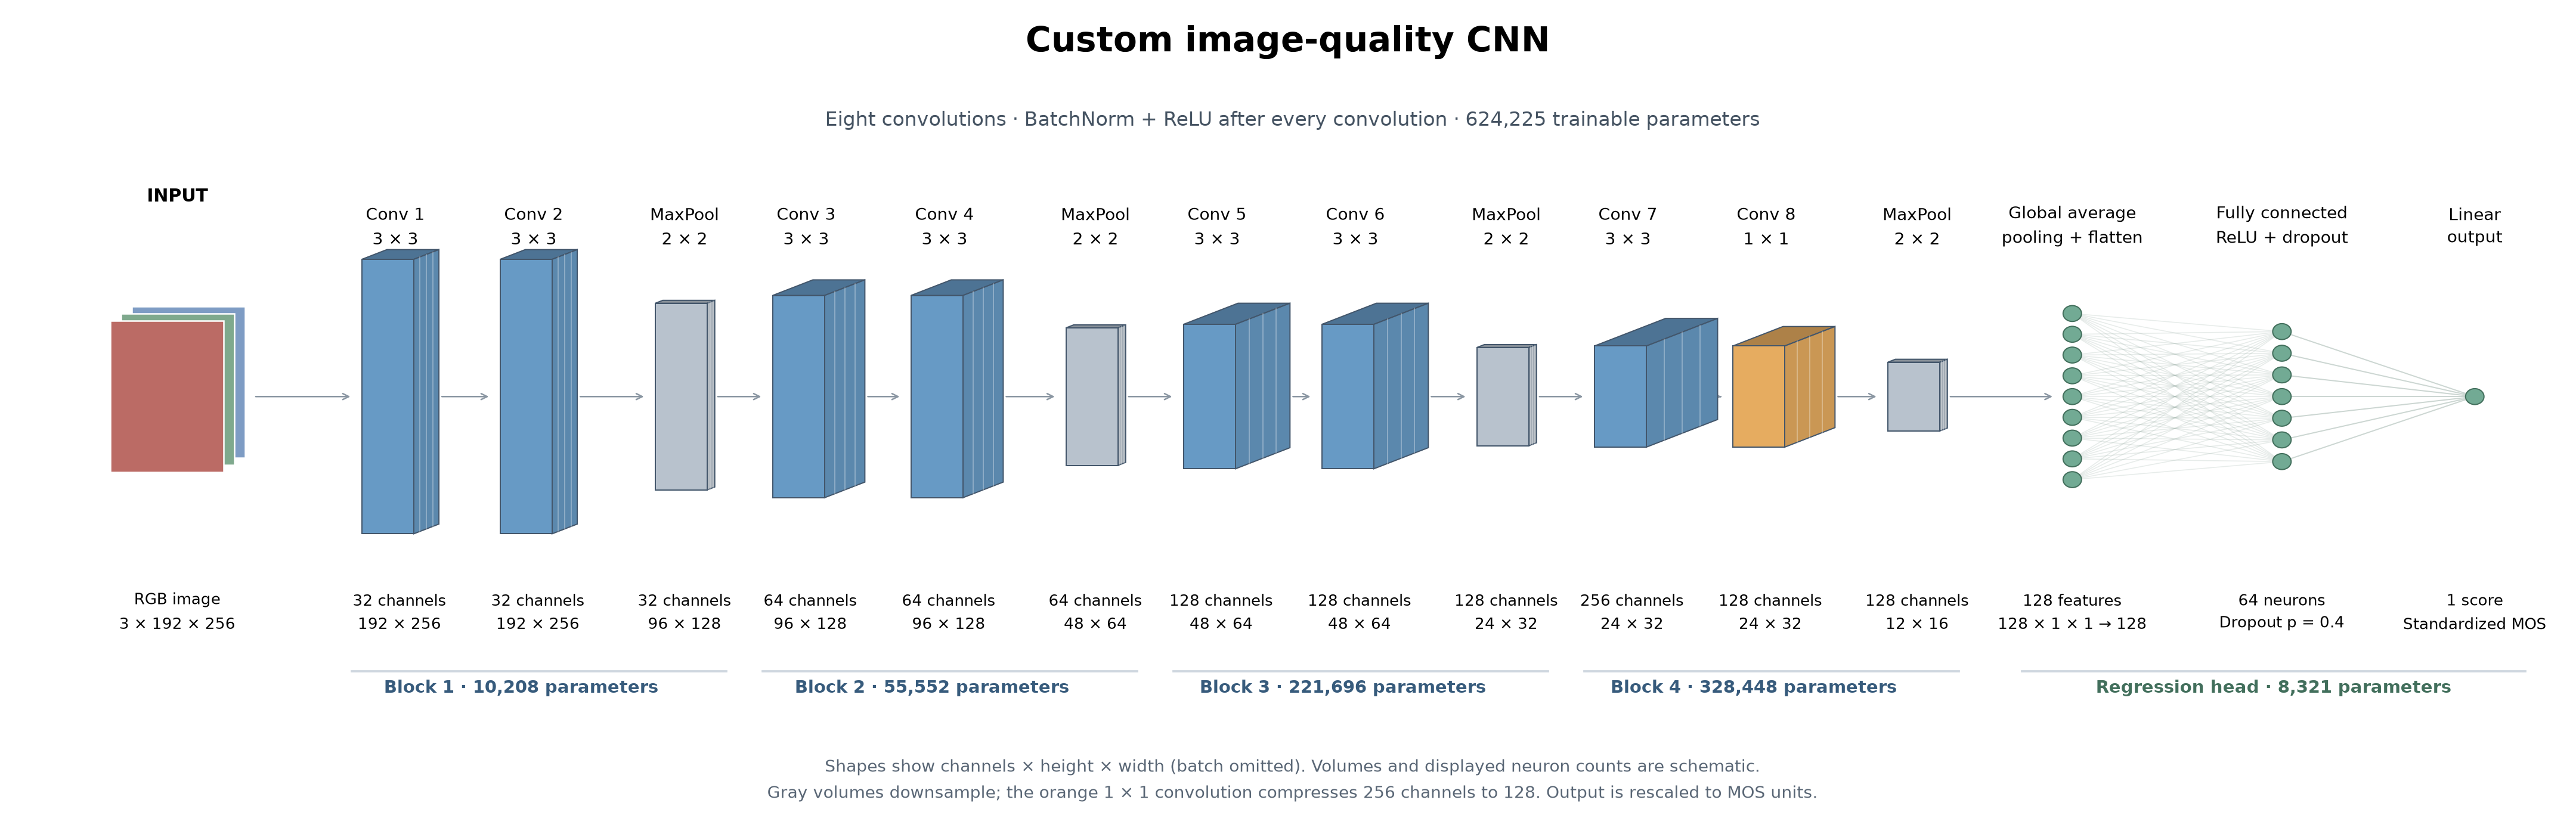

In [6]:
model = ScratchCNN()
model.eval()
layer_rows = []
handles = []
for name, layer in model.named_modules():
    if isinstance(
        layer, (nn.Conv2d, nn.BatchNorm2d, nn.MaxPool2d, nn.AdaptiveAvgPool2d, nn.Linear)
    ):

        def record(layer, inputs, output, name=name):
            layer_rows.append(
                {
                    "layer": name,
                    "operation": type(layer).__name__,
                    "output_shape": str(tuple(output.shape[1:])),
                    "parameters": sum(p.numel() for p in layer.parameters()),
                }
            )

        handles.append(layer.register_forward_hook(record))
with torch.no_grad():
    model(torch.zeros(1, 3, 192, 256))
for handle in handles:
    handle.remove()
architecture_table = pd.DataFrame(layer_rows)
display(architecture_table)
parameter_count = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {parameter_count:,}")
architecture_table.to_csv(OUTPUT / "scratch_architecture.csv", index=False)

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgb
from matplotlib.patches import Circle, Polygon, Rectangle


def draw_cnn_architecture():
    """Feature-map volumes and dense connections; dimensions are schematic."""
    fig, ax = plt.subplots(figsize=(24, 7.8))
    blue, orange, gray, green = "#679ac5", "#e6ac60", "#b8c2cd", "#72aa94"
    center_y = 1.6

    def volume(x, height, depth, color):
        width = 0.62
        bottom, top = center_y - height / 2, center_y + height / 2
        dx, dy = depth, depth * 0.45
        rgb = np.array(to_rgb(color))
        ax.add_patch(
            Polygon(
                [(x, top), (x + dx, top + dy), (x + width + dx, top + dy), (x + width, top)],
                facecolor=rgb * 0.75,
                edgecolor="#43566b",
                lw=0.8,
            )
        )
        ax.add_patch(
            Polygon(
                [
                    (x + width, bottom),
                    (x + width + dx, bottom + dy),
                    (x + width + dx, top + dy),
                    (x + width, top),
                ],
                facecolor=rgb * 0.88,
                edgecolor="#43566b",
                lw=0.8,
            )
        )
        ax.add_patch(
            Rectangle(
                (x, bottom),
                width,
                height,
                facecolor=color,
                edgecolor="#43566b",
                lw=0.8,
            )
        )
        # Fine divisions suggest channels without drawing every feature map.
        for fraction in [0.25, 0.5, 0.75]:
            ax.plot(
                [x + width + dx * fraction] * 2,
                [bottom + dy * fraction, top + dy * fraction],
                color="white",
                alpha=0.4,
                lw=0.6,
            )
        return x + width + dx

    def connection(start, end):
        ax.annotate(
            "",
            xy=(end, center_y),
            xytext=(start, center_y),
            arrowprops={"arrowstyle": "->", "color": "#8a96a2", "lw": 1.0},
            zorder=0,
        )

    def caption(x, text, y=-1.05):
        ax.text(x, y, text, ha="center", va="top", fontsize=10.5, linespacing=1.5)

    # Three offset planes represent the RGB image.
    for offset, color in reversed(list(enumerate(["#bb6b65", "#7fa98d", "#7e9cc4"]))):
        ax.add_patch(
            Rectangle(
                (0.1 + offset * 0.13, 0.55 + offset * 0.1),
                1.35,
                2.1,
                facecolor=color,
                edgecolor="white",
                lw=1,
            )
        )
    ax.text(0.9, 4.3, "INPUT", ha="center", weight="bold", fontsize=12)
    caption(0.9, "RGB image\n3 × 192 × 256")
    previous_end = 1.8

    blocks = [
        (3.1, 3.8, 0.30, 32, "192 × 256", "96 × 128", "10,208"),
        (8.0, 2.8, 0.48, 64, "96 × 128", "48 × 64", "55,552"),
        (12.9, 2.0, 0.65, 128, "48 × 64", "24 × 32", "221,696"),
        (17.8, 1.4, 0.85, 256, "24 × 32", "12 × 16", "328,448"),
    ]
    for number, (start, height, depth, channels, spatial, pooled, parameters) in enumerate(
        blocks, 1
    ):
        connection(previous_end, start - 0.1)
        first_end = volume(start, height, depth, blue)
        second_x = start + 1.65
        connection(first_end, second_x - 0.1)
        second_channels = 128 if number == 4 else channels
        second_end = volume(
            second_x, height, depth if number < 4 else 0.6, orange if number == 4 else blue
        )
        pool_x = start + 3.5
        connection(second_end, pool_x - 0.1)
        previous_end = volume(pool_x, height * 0.68, 0.09, gray)

        for x, label in [
            (start + 0.4, f"Conv {number * 2 - 1}\n3 × 3"),
            (second_x + 0.4, f"Conv {number * 2}\n{'1 × 1' if number == 4 else '3 × 3'}"),
            (pool_x + 0.35, "MaxPool\n2 × 2"),
        ]:
            ax.text(x, 4.3, label, ha="center", va="top", fontsize=11, linespacing=1.5)
        caption(start + 0.45, f"{channels} channels\n{spatial}")
        caption(second_x + 0.45, f"{second_channels} channels\n{spatial}")
        caption(pool_x + 0.35, f"{second_channels} channels\n{pooled}")
        ax.plot([start - 0.12, pool_x + 0.85], [-2.2, -2.2], color="#ced6df", lw=1.5)
        ax.text(
            start + 1.9,
            -2.5,
            f"Block {number} · {parameters} parameters",
            ha="center",
            fontsize=11.5,
            weight="bold",
            color="#375b7c",
        )

    # A few displayed nodes stand for each complete feature vector.
    feature_x, hidden_x, output_x = 23.5, 26.0, 28.3
    feature_y = np.linspace(0.45, 2.75, 9)
    hidden_y = np.linspace(0.7, 2.5, 7)
    connection(previous_end, feature_x - 0.2)
    for left in feature_y:
        for right in hidden_y:
            ax.plot([feature_x, hidden_x], [left, right], color="#9aafa6", alpha=0.23, lw=0.65)
    for y in hidden_y:
        ax.plot([hidden_x, output_x], [y, center_y], color="#9aafa6", alpha=0.5, lw=0.8)
    for x, positions in [(feature_x, feature_y), (hidden_x, hidden_y), (output_x, [center_y])]:
        for y in positions:
            ax.add_patch(
                Circle((x, y), 0.11, facecolor=green, edgecolor="#426f5c", lw=0.8, zorder=3)
            )
    ax.text(
        feature_x,
        4.3,
        "Global average\npooling + flatten",
        ha="center",
        va="top",
        fontsize=11,
        linespacing=1.5,
    )
    ax.text(
        hidden_x,
        4.3,
        "Fully connected\nReLU + dropout",
        ha="center",
        va="top",
        fontsize=11,
        linespacing=1.5,
    )
    ax.text(output_x, 4.3, "Linear\noutput", ha="center", va="top", fontsize=11, linespacing=1.5)
    caption(feature_x, "128 features\n128 × 1 × 1 → 128")
    caption(hidden_x, "64 neurons\nDropout p = 0.4")
    caption(output_x, "1 score\nStandardized MOS")
    ax.plot([feature_x - 0.6, output_x + 0.6], [-2.2, -2.2], color="#ced6df", lw=1.5)
    ax.text(
        (feature_x + output_x) / 2,
        -2.5,
        "Regression head · 8,321 parameters",
        ha="center",
        fontsize=11.5,
        weight="bold",
        color="#426f5c",
    )

    fig.suptitle("Custom image-quality CNN", fontsize=23, weight="bold", y=0.97)
    ax.text(
        14.2,
        5.35,
        "Eight convolutions · BatchNorm + ReLU after every convolution · 624,225 trainable parameters",
        ha="center",
        fontsize=13,
        color="#455362",
    )
    ax.text(
        14.2,
        -3.35,
        "Shapes show channels × height × width (batch omitted). Volumes and displayed neuron counts are schematic.\n"
        "Gray volumes downsample; the orange 1 × 1 convolution compresses 256 channels to 128. Output is rescaled to MOS units.",
        ha="center",
        va="top",
        fontsize=11,
        color="#596675",
        linespacing=1.6,
    )
    ax.set(xlim=(-0.6, 29.2), ylim=(-4.15, 5.7), aspect="auto")
    ax.axis("off")
    fig.subplots_adjust(left=0.02, right=0.99, top=0.88, bottom=0.03)
    return fig


fig = draw_cnn_architecture()
fig.savefig(OUTPUT / "scratch_architecture.png", dpi=180, facecolor="white")
fig.savefig(OUTPUT / "scratch_architecture.svg", facecolor="white")
plt.show()
del model


## 4. Training and validation
We minimize MSE on standardized MOS using AdamW. Each epoch records training and validation
MSE, MAE, RMSE, and SROCC. Training metrics use a separate unaugmented training loader, with
dropout disabled, to make the learning curves comparable. A100 execution uses bfloat16
mixed precision; losses and reported predictions use float32.

A checkpoint is saved whenever validation SROCC improves (lower RMSE breaks exact ties).
Early stopping counts epochs without improvement and restores that checkpoint. All runs
start from seed 42; settings and checkpoint selection never use test results.

In [7]:
"""Plain training, validation, checkpointing, and plots for image-quality regression."""

import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr
from torch import nn


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def regression_scores(targets, predictions):
    targets, predictions = np.asarray(targets).ravel(), np.asarray(predictions).ravel()
    errors = predictions - targets
    correlation = (
        float(spearmanr(targets, predictions).statistic)
        if np.std(predictions) > 0
        else float("nan")
    )
    return {
        "srocc": correlation,
        "mae": float(np.abs(errors).mean()),
        "rmse": float(np.sqrt(np.square(errors).mean())),
    }


@torch.no_grad()
def evaluate(model, loader, device, target_mean, target_std):
    model.eval()
    predictions, targets, loss_sum = [], [], 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=device.type == "cuda"):
            output = model(images)
        loss_sum += nn.functional.mse_loss(output.float(), labels, reduction="sum").item()
        predictions.append(output.float().cpu().numpy())
        targets.append(labels.cpu().numpy())
    predictions = np.concatenate(predictions).ravel() * target_std + target_mean
    targets = np.concatenate(targets).ravel() * target_std + target_mean
    scores = regression_scores(targets, predictions)
    scores["loss"] = loss_sum / len(loader.dataset)
    return scores, targets, predictions


def train_model(
    model,
    loaders,
    settings,
    output_dir,
    device,
    target_mean,
    target_std,
    channel_mean,
    channel_std,
    epochs=15,
    patience=None,
):
    """Train on training images; restore the checkpoint with best validation SROCC."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    model = model.to(device)
    optimizer = optimizer_for(model, settings["learning_rate"])
    evaluation_transform = loaders["validation"].dataset.transform
    image_mean, image_std = channel_mean, channel_std
    if not isinstance(model, ScratchCNN):
        image_mean, image_std = evaluation_transform.mean, evaluation_transform.std
    history, best_scores, best_epoch, stale_epochs = [], None, 0, 0
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        set_training_mode(model)
        for images, labels in loaders["training"]:
            images, labels = images.to(device, non_blocking=True), labels.to(
                device, non_blocking=True
            )
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=device.type == "cuda"):
                predictions = model(images)
                loss = nn.functional.mse_loss(predictions.float(), labels)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Nonfinite training loss in {output_dir.name}")
            loss.backward()
            optimizer.step()
        # Measure both splits without augmentation or dropout for comparable curves.
        train_scores, _, _ = evaluate(model, loaders["train_eval"], device, target_mean, target_std)
        val_scores, _, _ = evaluate(model, loaders["validation"], device, target_mean, target_std)
        history.append(
            {
                "epoch": epoch,
                **{f"train_{k}": v for k, v in train_scores.items()},
                **{f"val_{k}": v for k, v in val_scores.items()},
                "seconds": time.perf_counter() - start,
            }
        )
        pd.DataFrame(history).to_csv(output_dir / "history.csv", index=False)
        current_score = np.nan_to_num(val_scores["srocc"], nan=-np.inf)
        previous_score = (
            -np.inf if best_scores is None else np.nan_to_num(best_scores["srocc"], nan=-np.inf)
        )
        improved = best_scores is None or (current_score, -val_scores["rmse"]) > (
            previous_score,
            -best_scores["rmse"],
        )
        # Save by validation ranking, using RMSE only to break an exact tie.
        if improved:
            best_scores, best_epoch, stale_epochs = val_scores.copy(), epoch, 0
            torch.save(
                {
                    "model_state": model.state_dict(),
                    "settings": settings,
                    "best_epoch": best_epoch,
                    "validation": best_scores,
                    "target_mean": target_mean,
                    "target_std": target_std,
                    "channel_mean": image_mean,
                    "channel_std": image_std,
                    "evaluation_preprocessing": repr(evaluation_transform),
                    "seed": 42,
                    "crop_area": [0.8, 1.0],
                    "weight_decay": 1e-4,
                    "epoch_budget": epochs,
                    "patience": patience,
                    "batch_size": loaders["training"].batch_size,
                },
                output_dir / "best.pt",
            )
        else:
            stale_epochs += 1
        print(
            f"{output_dir.name} | {epoch:02d}/{epochs} | "
            f"train MAE {train_scores['mae']:.3f} | val MAE {val_scores['mae']:.3f} | "
            f"val SROCC {val_scores['srocc']:.4f} | {history[-1]['seconds']:.0f}s",
            flush=True,
        )
        if patience is not None and stale_epochs >= patience:
            print(f"Early stopping; restoring epoch {best_epoch}.", flush=True)
            break
    checkpoint = torch.load(output_dir / "best.pt", map_location="cpu", weights_only=True)
    model.load_state_dict(checkpoint["model_state"])
    model.cpu()
    result = {
        **settings,
        "best_epoch": best_epoch,
        "stopped_epoch": epoch,
        **{f"val_{k}": v for k, v in best_scores.items()},
        "seconds": time.perf_counter() - start,
        "checkpoint": str(output_dir / "best.pt"),
    }
    pd.DataFrame([result]).to_csv(output_dir / "result.csv", index=False)
    return result, pd.DataFrame(history)


def plot_history(history, best_epoch, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, metric, label in zip(
        axes, ["loss", "mae", "srocc"], ["MSE (standardized MOS)", "MAE (MOS units)", "SROCC"]
    ):
        ax.plot(history.epoch, history[f"train_{metric}"], label="Training")
        ax.plot(history.epoch, history[f"val_{metric}"], label="Validation")
        ax.axvline(best_epoch, color="0.4", linestyle=":", label="Best checkpoint")
        ax.set(xlabel="Epoch", ylabel=label)
        ax.grid(alpha=0.2)
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


@torch.no_grad()
def extract_features(model, loader, device, target_mean, target_std):
    """Read the input to the saved model's final scalar prediction layer."""
    model.eval().to(device)
    final_layer = [layer for layer in model.modules() if isinstance(layer, nn.Linear)][-1]
    captured = []
    handle = final_layer.register_forward_pre_hook(
        lambda layer, inputs: captured.append(inputs[0].detach().float().cpu())
    )
    labels = []
    try:
        for images, targets in loader:
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=device.type == "cuda"):
                model(images.to(device))
            labels.append(targets.numpy())
    finally:
        handle.remove()
        model.cpu()
    return torch.cat(captured).numpy(), np.concatenate(labels).ravel() * target_std + target_mean


## 5. Hyperparameter comparison
Four settings vary learning rate and head dropout. All use the same architecture,
batch size 64, weight decay `1e-4`, and a 15-epoch tuning budget. We select the setting
with the highest best validation SROCC. This is one seeded course comparison.

In [8]:
scratch_settings = [
    {"model": "scratch", "learning_rate": 1e-3, "dropout": 0.2},
    {"model": "scratch", "learning_rate": 1e-3, "dropout": 0.4},
    {"model": "scratch", "learning_rate": 3e-4, "dropout": 0.2},
    {"model": "scratch", "learning_rate": 3e-4, "dropout": 0.4},
]
# Each setting starts from the same seed and a fresh model.
scratch_results = []
for index, settings in enumerate(scratch_settings):
    set_seed(SEED)
    model = ScratchCNN(settings["dropout"])
    loaders = make_loaders(
        splits, "scratch", channel_mean, channel_std, target_mean, target_std, BATCH_SIZE, WORKERS
    )
    result, history = train_model(
        model,
        loaders,
        settings,
        OUTPUT / f"scratch_tuning_{index+1}",
        DEVICE,
        target_mean,
        target_std,
        channel_mean,
        channel_std,
        epochs=TUNING_EPOCHS,
    )
    scratch_results.append(result)
    del model, loaders
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
scratch_table = pd.DataFrame(scratch_results)
scratch_table.to_csv(OUTPUT / "scratch_tuning.csv", index=False)
display(scratch_table.drop(columns="checkpoint"))
best_scratch = max(scratch_results, key=lambda r: (r["val_srocc"], -r["val_rmse"]))
selected_scratch_settings = {
    key: best_scratch[key] for key in ["model", "learning_rate", "dropout"]
}
print("Selected scratch settings:", selected_scratch_settings)


scratch_tuning_1 | 01/15 | train MAE 9.787 | val MAE 9.546 | val SROCC 0.6185 | 19s
scratch_tuning_1 | 15/15 | train MAE 8.589 | val MAE 8.697 | val SROCC 0.7311 | 213s
scratch_tuning_2 | 01/15 | train MAE 8.988 | val MAE 8.832 | val SROCC 0.6143 | 15s
scratch_tuning_2 | 15/15 | train MAE 7.960 | val MAE 7.986 | val SROCC 0.7194 | 211s
scratch_tuning_3 | 01/15 | train MAE 9.562 | val MAE 9.360 | val SROCC 0.6224 | 15s
scratch_tuning_3 | 15/15 | train MAE 7.322 | val MAE 7.606 | val SROCC 0.7316 | 214s
scratch_tuning_4 | 01/15 | train MAE 9.425 | val MAE 9.203 | val SROCC 0.6209 | 15s
scratch_tuning_4 | 15/15 | train MAE 8.506 | val MAE 8.754 | val SROCC 0.7205 | 214s


,model,learning_rate,dropout,best_epoch,stopped_epoch,val_srocc,val_mae,val_rmse,val_loss,seconds
0,scratch,0.0010,0.2,15,15,0.731062,8.696870,10.819736,0.485190,213.021737
1,scratch,0.0010,0.4,11,15,0.731727,8.096275,10.339870,0.443107,211.342082
2,scratch,0.0003,0.2,15,15,0.731633,7.605566,9.858336,0.402797,213.750001
3,scratch,0.0003,0.4,11,15,0.724525,8.086288,10.301767,0.439848,213.603883


Selected scratch settings: {'model': 'scratch', 'learning_rate': 0.001, 'dropout': 0.4}


## 6. Early stopping comparison
Using the selected hyperparameters, we train fresh models from the same seed: one for
30 epochs without early stopping and one for up to 30 epochs with patience 5.
Both restore their best validation checkpoint. We compare their validation metrics and
learning curves, then retain the better checkpoint for final test evaluation.

scratch_fixed_budget | 01/30 | train MAE 8.988 | val MAE 8.832 | val SROCC 0.6143 | 15s
scratch_fixed_budget | 30/30 | train MAE 7.560 | val MAE 7.907 | val SROCC 0.7296 | 423s


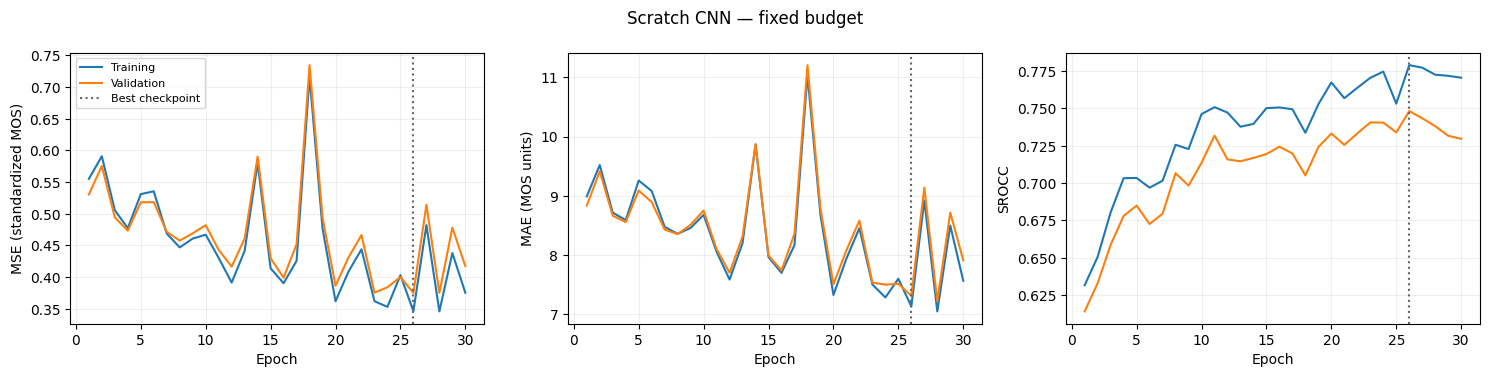

scratch_early_stopping | 01/30 | train MAE 8.988 | val MAE 8.832 | val SROCC 0.6143 | 15s
scratch_early_stopping | 16/30 | train MAE 7.694 | val MAE 7.735 | val SROCC 0.7243 | 227s
Early stopping; restoring epoch 11.


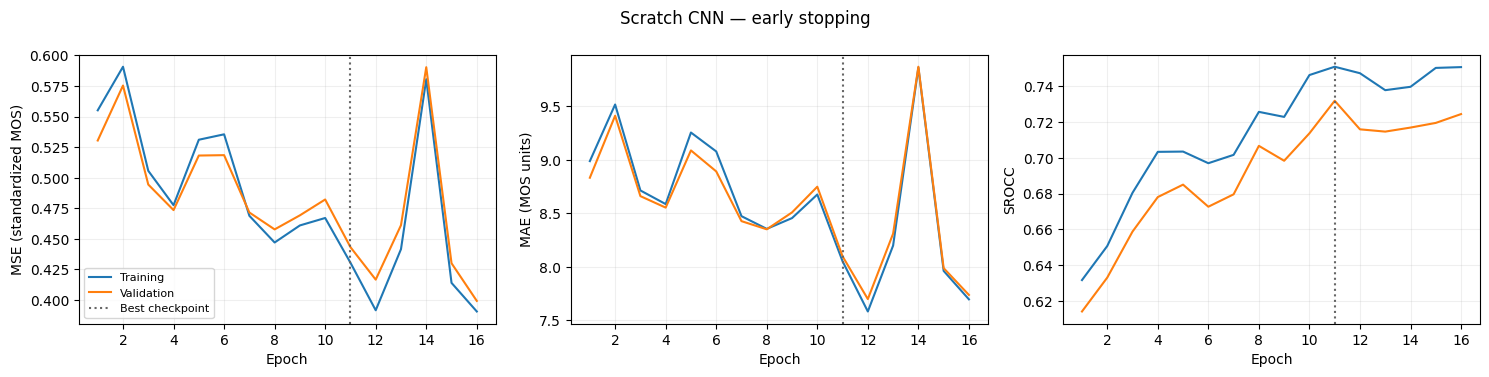

,model,learning_rate,dropout,training,best_epoch,stopped_epoch,val_srocc,val_mae,val_rmse,val_loss,seconds
0,scratch,0.001,0.4,fixed_budget,26,30,0.748081,7.305522,9.512816,0.375057,422.537915
1,scratch,0.001,0.4,early_stopping,11,16,0.731727,8.096275,10.339870,0.443107,226.769101


Selected scratch checkpoint: fixed_budget epoch 26


In [9]:
scratch_final_results = []
scratch_histories = {}
for name, patience in [("fixed_budget", None), ("early_stopping", 5)]:
    set_seed(SEED)
    model = ScratchCNN(selected_scratch_settings["dropout"])
    loaders = make_loaders(
        splits, "scratch", channel_mean, channel_std, target_mean, target_std, BATCH_SIZE, WORKERS
    )
    settings = {**selected_scratch_settings, "training": name}
    result, history = train_model(
        model,
        loaders,
        settings,
        OUTPUT / f"scratch_{name}",
        DEVICE,
        target_mean,
        target_std,
        channel_mean,
        channel_std,
        epochs=FINAL_EPOCHS,
        patience=patience,
    )
    scratch_final_results.append(result)
    scratch_histories[name] = history
    figure = plot_history(history, result["best_epoch"], f"Scratch CNN — {name.replace('_', ' ')}")
    figure.savefig(OUTPUT / f"scratch_{name}_curves.png", dpi=160)
    plt.show()
    del model, loaders
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
scratch_final_table = pd.DataFrame(scratch_final_results)
display(scratch_final_table.drop(columns="checkpoint"))
scratch_final_table.to_csv(OUTPUT / "early_stopping_comparison.csv", index=False)
selected_scratch = max(scratch_final_results, key=lambda r: (r["val_srocc"], -r["val_rmse"]))
print(
    "Selected scratch checkpoint:",
    selected_scratch["training"],
    "epoch",
    selected_scratch["best_epoch"],
)


## 7. Transfer learning and partial fine-tuning
We use ImageNet-pretrained **VGG19, ResNet50, and InceptionV3**. Each produces one linear
regression output. All three models are trained under each of these configurations:

| Configuration | Trainable layers |
|---|---|
| Head only | New scalar output layer; pretrained parameters frozen |
| Last three | The three named Conv/Linear layers below; all other parameters frozen |
| Expanded head | New four-linear-layer head with ReLU/dropout; pretrained parameters frozen |

We interpret “freeze all ... last 3 layers” as freezing everything **except** the final
three selected learnable layers. ReLU, pooling, dropout, and BatchNorm do not count toward
these three. Inception branches, so its two selected convolutions are parallel terminal
layers on the deepest branch of its last Inception block, rather than a sequential tail.

| Model | Exact layers for partial fine-tuning |
|---|---|
| VGG19 | `classifier.0`, `classifier.3`, `classifier.6` |
| ResNet50 | `layer4.2.conv2`, `layer4.2.conv3`, `fc` |
| InceptionV3 | `Mixed_7c.branch3x3dbl_3a.conv`, `Mixed_7c.branch3x3dbl_3b.conv`, `fc` |

The new output layer uses the selected head learning rate; pretrained trainable layers
use one tenth of that rate. Frozen-backbone BatchNorm statistics remain fixed. Inception's
auxiliary classifier is disabled. The following inspection uses architecture definitions
without weights; actual training below loads the pretrained weights.

In [10]:
layer_tables = []
for model_name in ["vgg19", "resnet50", "inception_v3"]:
    for mode in ["head_only", "last_three", "expanded_head"]:
        with torch.device("meta"):
            model = build_pretrained(model_name, mode, pretrained=False)
        table = trainable_layer_table(model)
        table.insert(0, "configuration", mode)
        table.insert(0, "model", model_name)
        layer_tables.append(table)
        del model
trainable_layers = pd.concat(layer_tables, ignore_index=True)
display(trainable_layers)
trainable_layers.to_csv(OUTPUT / "trainable_layers.csv", index=False)
display(
    trainable_layers.groupby(["model", "configuration"], sort=False)
    .trainable_parameters.sum()
    .reset_index()
)


,model,configuration,layer,type,trainable_parameters
0,vgg19,head_only,classifier.6,Linear,4097
1,vgg19,last_three,classifier.0,Linear,102764544
2,vgg19,last_three,classifier.3,Linear,16781312
3,vgg19,last_three,classifier.6,Linear,4097
4,vgg19,expanded_head,classifier.0,Linear,12845568
5,vgg19,expanded_head,classifier.3,Linear,131328
6,vgg19,expanded_head,classifier.6,Linear,16448
7,vgg19,expanded_head,classifier.8,Linear,65
8,resnet50,head_only,fc,Linear,2049
9,resnet50,last_three,layer4.2.conv2,Conv2d,2359296


,model,configuration,trainable_parameters
0,vgg19,head_only,4097
1,vgg19,last_three,119549953
2,vgg19,expanded_head,12993409
3,resnet50,head_only,2049
4,resnet50,last_three,3409921
5,resnet50,expanded_head,1196929
6,inception_v3,head_only,2049
7,inception_v3,last_three,886785
8,inception_v3,expanded_head,1196929


### Select a learning rate on validation data
For each architecture, compare head learning rates `1e-3` and `1e-4` in fresh three-epoch
head-only pilot runs. Choose by best validation SROCC. Use that rate for its new layers
in the three full configurations; pretrained layers in partial fine-tuning use one tenth
of it. Pilots never use test data and are separate from the final 15-epoch training runs.

In [11]:
pilot_results = []
transfer_learning_rates = {}
for model_name in ["vgg19", "resnet50", "inception_v3"]:
    for learning_rate in [1e-3, 1e-4]:
        set_seed(SEED)
        model = build_pretrained(model_name, "head_only")
        loaders = make_loaders(
            splits,
            model_name,
            channel_mean,
            channel_std,
            target_mean,
            target_std,
            BATCH_SIZE,
            WORKERS,
        )
        settings = {"model": model_name, "mode": "head_only", "learning_rate": learning_rate}
        result, history = train_model(
            model,
            loaders,
            settings,
            OUTPUT / f"pilot_{model_name}_{learning_rate:g}",
            DEVICE,
            target_mean,
            target_std,
            channel_mean,
            channel_std,
            epochs=3,
        )
        pilot_results.append(result)
        del model, loaders
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    candidates = [r for r in pilot_results if r["model"] == model_name]
    transfer_learning_rates[model_name] = max(
        candidates, key=lambda r: (r["val_srocc"], -r["val_rmse"])
    )["learning_rate"]
pilot_table = pd.DataFrame(pilot_results)
pilot_table.to_csv(OUTPUT / "learning_rate_pilots.csv", index=False)
display(pilot_table.drop(columns="checkpoint"))
print("Selected head learning rates:", transfer_learning_rates)


pilot_vgg19_0.001 | 01/3 | train MAE 8.218 | val MAE 8.650 | val SROCC 0.6512 | 16s
pilot_vgg19_0.001 | 03/3 | train MAE 7.628 | val MAE 8.616 | val SROCC 0.6759 | 48s
pilot_vgg19_0.0001 | 01/3 | train MAE 9.448 | val MAE 9.233 | val SROCC 0.5915 | 16s
pilot_vgg19_0.0001 | 03/3 | train MAE 8.540 | val MAE 8.603 | val SROCC 0.6566 | 48s
pilot_resnet50_0.001 | 01/3 | train MAE 8.274 | val MAE 8.480 | val SROCC 0.6723 | 15s
pilot_resnet50_0.001 | 03/3 | train MAE 7.444 | val MAE 8.049 | val SROCC 0.7118 | 45s
pilot_resnet50_0.0001 | 01/3 | train MAE 11.586 | val MAE 11.270 | val SROCC 0.4190 | 16s
pilot_resnet50_0.0001 | 03/3 | train MAE 10.016 | val MAE 9.888 | val SROCC 0.5877 | 45s
pilot_inception_v3_0.001 | 01/3 | train MAE 9.170 | val MAE 9.073 | val SROCC 0.5847 | 21s
pilot_inception_v3_0.001 | 03/3 | train MAE 8.432 | val MAE 8.651 | val SROCC 0.6426 | 60s
pilot_inception_v3_0.0001 | 01/3 | train MAE 11.549 | val MAE 11.104 | val SROCC 0.4045 | 21s
pilot_inception_v3_0.0001 | 03/3 

,model,mode,learning_rate,best_epoch,stopped_epoch,val_srocc,val_mae,val_rmse,val_loss,seconds
0,vgg19,head_only,0.0010,3,3,0.675882,8.616344,10.997444,0.501259,50.030334
1,vgg19,head_only,0.0001,3,3,0.656557,8.603443,11.025360,0.503807,50.204904
2,resnet50,head_only,0.0010,3,3,0.711788,8.049491,10.190669,0.430412,45.013069
3,resnet50,head_only,0.0001,3,3,0.587697,9.888409,12.256487,0.622602,45.661100
4,inception_v3,head_only,0.0010,3,3,0.642558,8.651381,11.020534,0.503366,60.392174
5,inception_v3,head_only,0.0001,3,3,0.543491,9.864323,12.365017,0.633677,60.594702


Selected head learning rates: {'vgg19': 0.001, 'resnet50': 0.001, 'inception_v3': 0.001}


### Train all nine configurations
Each full experiment starts again from the original pretrained weights and seed 42.
Training lasts at most 15 epochs with early-stopping patience 4. The best checkpoint
from every run is saved. The overall winner is selected only by validation results.

vgg19_head_only | 01/15 | train MAE 8.218 | val MAE 8.650 | val SROCC 0.6512 | 16s
vgg19_head_only | 07/15 | train MAE 7.245 | val MAE 8.860 | val SROCC 0.6478 | 112s
Early stopping; restoring epoch 3.
vgg19_last_three | 01/15 | train MAE 7.392 | val MAE 8.079 | val SROCC 0.6958 | 16s
vgg19_last_three | 15/15 | train MAE 4.814 | val MAE 8.062 | val SROCC 0.7181 | 234s
Early stopping; restoring epoch 11.
vgg19_expanded_head | 01/15 | train MAE 7.893 | val MAE 8.256 | val SROCC 0.6864 | 16s
vgg19_expanded_head | 07/15 | train MAE 5.374 | val MAE 7.994 | val SROCC 0.7031 | 107s
Early stopping; restoring epoch 3.
resnet50_head_only | 01/15 | train MAE 8.274 | val MAE 8.480 | val SROCC 0.6723 | 15s
resnet50_head_only | 07/15 | train MAE 6.864 | val MAE 7.983 | val SROCC 0.7010 | 104s
Early stopping; restoring epoch 3.
resnet50_last_three | 01/15 | train MAE 7.324 | val MAE 7.793 | val SROCC 0.7135 | 16s
resnet50_last_three | 08/15 | train MAE 3.981 | val MAE 7.584 | val SROCC 0.7341 | 121s


,model,mode,learning_rate,best_epoch,stopped_epoch,val_srocc,val_mae,val_rmse,val_loss,seconds
0,vgg19,head_only,0.001,3,7,0.675882,8.616344,10.997444,0.501259,112.582011
1,vgg19,last_three,0.001,11,15,0.724836,7.721686,9.927100,0.408436,235.128390
2,vgg19,expanded_head,0.001,3,7,0.713242,7.932385,10.070568,0.420326,106.974424
3,resnet50,head_only,0.001,3,7,0.711788,8.049491,10.190669,0.430412,104.681502
4,resnet50,last_three,0.001,4,8,0.746964,7.848717,9.811340,0.398966,121.177782
5,resnet50,expanded_head,0.001,2,6,0.713509,7.656732,10.184542,0.429894,89.910823
6,inception_v3,head_only,0.001,4,8,0.646834,8.691963,11.014595,0.502824,158.070742
7,inception_v3,last_three,0.001,5,9,0.647634,8.713790,11.035548,0.504739,183.540406
8,inception_v3,expanded_head,0.001,8,12,0.650339,8.490187,10.805129,0.483881,238.901471


mode,expanded_head,head_only,last_three
model,,,
inception_v3,0.650339,0.646834,0.647634
resnet50,0.713509,0.711788,0.746964
vgg19,0.713242,0.675882,0.724836


Saved validation-selected transfer model: resnet50 last_three


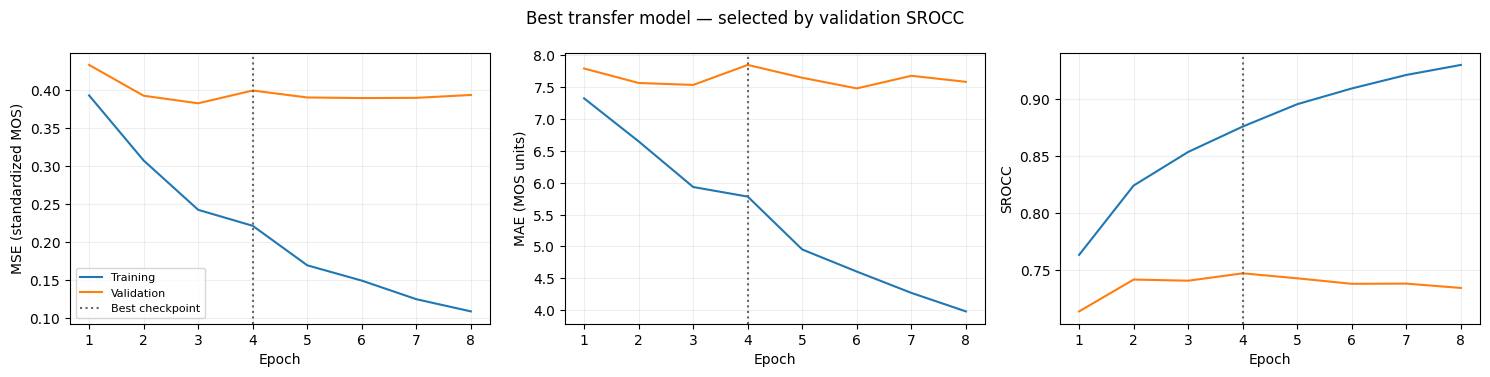

In [12]:
transfer_results = []
transfer_histories = {}
for model_name in ["vgg19", "resnet50", "inception_v3"]:
    for mode in ["head_only", "last_three", "expanded_head"]:
        set_seed(SEED)
        model = build_pretrained(model_name, mode)
        loaders = make_loaders(
            splits,
            model_name,
            channel_mean,
            channel_std,
            target_mean,
            target_std,
            BATCH_SIZE,
            WORKERS,
        )
        settings = {
            "model": model_name,
            "mode": mode,
            "learning_rate": transfer_learning_rates[model_name],
        }
        result, history = train_model(
            model,
            loaders,
            settings,
            OUTPUT / f"{model_name}_{mode}",
            DEVICE,
            target_mean,
            target_std,
            channel_mean,
            channel_std,
            epochs=TRANSFER_EPOCHS,
            patience=4,
        )
        transfer_results.append(result)
        transfer_histories[(model_name, mode)] = history
        pd.DataFrame(transfer_results).to_csv(OUTPUT / "transfer_comparison.csv", index=False)
        del model, loaders
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
transfer_table = pd.DataFrame(transfer_results)
display(transfer_table.drop(columns="checkpoint"))
display(transfer_table.pivot(index="model", columns="mode", values="val_srocc"))
selected_transfer = max(transfer_results, key=lambda r: (r["val_srocc"], -r["val_rmse"]))
shutil.copy2(selected_transfer["checkpoint"], OUTPUT / "best_transfer.pt")
print(
    "Saved validation-selected transfer model:",
    selected_transfer["model"],
    selected_transfer["mode"],
)
figure = plot_history(
    transfer_histories[(selected_transfer["model"], selected_transfer["mode"])],
    selected_transfer["best_epoch"],
    "Best transfer model — selected by validation SROCC",
)
figure.savefig(OUTPUT / "best_transfer_curves.png", dpi=160)
plt.show()


## 8. Saved model as a feature extractor: SVR
We reload `best_transfer.pt` and extract its feature vector immediately before the scalar
output. The CNN remains frozen and in evaluation mode. Deterministic preprocessing is used
for training, validation, and test feature extraction. StandardScaler is fitted only on
training features; SVR is fitted only on training MOS. We compare `C=1, 10, 100` on validation
SROCC with an RBF kernel, `gamma="scale"`, and epsilon 1 MOS point.

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
import joblib

# Reload the validation-selected CNN before extracting frozen features.
checkpoint = torch.load(OUTPUT / "best_transfer.pt", map_location="cpu", weights_only=True)
settings = checkpoint["settings"]
feature_model = build_pretrained(settings["model"], settings["mode"], pretrained=False)
feature_model.load_state_dict(checkpoint["model_state"])
for parameter in feature_model.parameters():
    parameter.requires_grad = False
feature_loaders = make_loaders(
    splits,
    settings["model"],
    channel_mean,
    channel_std,
    target_mean,
    target_std,
    BATCH_SIZE,
    WORKERS,
)
train_features, train_mos = extract_features(
    feature_model, feature_loaders["train_eval"], DEVICE, target_mean, target_std
)
val_features, val_mos = extract_features(
    feature_model, feature_loaders["validation"], DEVICE, target_mean, target_std
)
print("Feature shapes:", train_features.shape, val_features.shape)
svr_results, svr_models = [], []
for c_value in [1.0, 10.0, 100.0]:
    svr = make_pipeline(StandardScaler(), SVR(C=c_value, epsilon=1.0, gamma="scale"))
    svr.fit(train_features, train_mos)
    scores = regression_scores(val_mos, svr.predict(val_features))
    svr_results.append({"C": c_value, **{f"val_{k}": v for k, v in scores.items()}})
    svr_models.append(svr)
svr_table = pd.DataFrame(svr_results)
display(svr_table)
svr_table.to_csv(OUTPUT / "svr_validation.csv", index=False)
best_svr_index = max(
    range(len(svr_results)),
    key=lambda i: (svr_results[i]["val_srocc"], -svr_results[i]["val_rmse"]),
)
selected_svr = svr_models[best_svr_index]
joblib.dump(selected_svr, OUTPUT / "best_svr.joblib")
print("Selected SVR C:", svr_results[best_svr_index]["C"])


Feature shapes: (6446, 2048) (1612, 2048)


,C,val_srocc,val_mae,val_rmse
0,1.0,0.689232,8.676641,11.215070
1,10.0,0.728921,7.622152,9.794339
2,100.0,0.712078,7.823353,9.935652


Selected SVR C: 10.0


## 9. Final held-out test comparison
All choices are now fixed. We evaluate the selected scratch CNN, the nine transfer
configurations required for comparison, and the validation-selected SVR. M2 rows below
are the previously reported test results, not newly trained MLPs. Higher SROCC and lower
MAE/RMSE indicate better performance. No test result is used to revise settings.

,model,srocc,mae,rmse
0,M2 shallow MLP,0.471036,10.655842,13.485918
1,M2 deep MLP,0.479005,10.451660,13.253497
2,Scratch CNN,0.755971,7.336817,9.620028
3,vgg19 / head_only,0.657984,8.823699,11.301983
4,vgg19 / last_three,0.732198,7.788364,10.000195
5,vgg19 / expanded_head,0.720569,8.003713,10.206306
6,resnet50 / head_only,0.701958,8.153409,10.382860
7,resnet50 / last_three,0.756679,7.746076,9.638959
8,resnet50 / expanded_head,0.722956,7.563487,10.106277
9,inception_v3 / head_only,0.644582,8.794660,11.153813


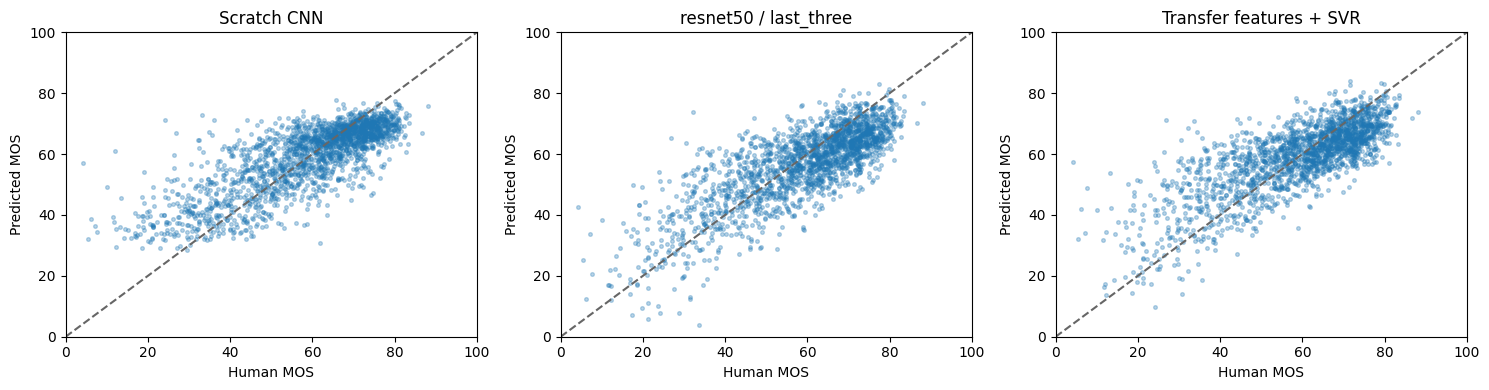

Scratch CNN versus M2 deep MLP: SROCC difference +0.2770; MAE difference -3.115 MOS points.
Scratch CNN exceeds the M2 deep MLP on test SROCC: True
Transfer winner was fixed using validation: resnet50 last_three


In [14]:
# Model and hyperparameter choices are fixed before touching these test loaders.
test_rows = [
    {"model": "M2 shallow MLP", "srocc": 0.471036, "mae": 10.655842, "rmse": 13.485918},
    {"model": "M2 deep MLP", "srocc": 0.479005, "mae": 10.451660, "rmse": 13.253497},
]
selected_predictions = {}
all_cnn_results = [selected_scratch, *transfer_results]
for result in all_cnn_results:
    saved = torch.load(result["checkpoint"], map_location="cpu", weights_only=True)
    settings = saved["settings"]
    model_name = settings["model"]
    model = (
        ScratchCNN(settings["dropout"])
        if model_name == "scratch"
        else build_pretrained(model_name, settings["mode"], pretrained=False)
    )
    model.load_state_dict(saved["model_state"])
    model.to(DEVICE)
    loaders = make_loaders(
        splits, model_name, channel_mean, channel_std, target_mean, target_std, BATCH_SIZE, WORKERS
    )
    scores, targets, predictions = evaluate(model, loaders["test"], DEVICE, target_mean, target_std)
    label = "Scratch CNN" if model_name == "scratch" else f"{model_name} / {settings['mode']}"
    test_rows.append({"model": label, **{k: scores[k] for k in ["srocc", "mae", "rmse"]}})
    pd.DataFrame(
        {"image_name": splits["test"].image_name, "MOS": targets, "prediction": predictions}
    ).to_csv(
        OUTPUT / (label.replace(" / ", "_").replace(" ", "_") + "_test_predictions.csv"),
        index=False,
    )
    if model_name == "scratch" or (
        model_name == selected_transfer["model"]
        and settings.get("mode") == selected_transfer["mode"]
    ):
        selected_predictions[label] = (targets, predictions)
    del model, loaders, saved
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
test_features, test_mos = extract_features(
    feature_model, feature_loaders["test"], DEVICE, target_mean, target_std
)
svr_predictions = selected_svr.predict(test_features)
test_rows.append(
    {"model": "Best transfer features + SVR", **regression_scores(test_mos, svr_predictions)}
)
pd.DataFrame(
    {"image_name": splits["test"].image_name, "MOS": test_mos, "prediction": svr_predictions}
).to_csv(OUTPUT / "svr_test_predictions.csv", index=False)
selected_predictions["Transfer features + SVR"] = (test_mos, svr_predictions)
test_table = pd.DataFrame(test_rows)
test_table.to_csv(OUTPUT / "test_comparison.csv", index=False)
display(test_table)
fig, axes = plt.subplots(1, len(selected_predictions), figsize=(15, 4))
for ax, (name, (actual, predicted)) in zip(axes, selected_predictions.items()):
    ax.scatter(actual, predicted, s=7, alpha=0.3)
    ax.plot([0, 100], [0, 100], linestyle="--", color="0.4")
    ax.set(title=name, xlabel="Human MOS", ylabel="Predicted MOS", xlim=(0, 100), ylim=(0, 100))
fig.tight_layout()
fig.savefig(OUTPUT / "test_predictions.png", dpi=160)
plt.show()

scratch_test = test_table[test_table.model == "Scratch CNN"].iloc[0]
print(
    f"Scratch CNN versus M2 deep MLP: SROCC difference {scratch_test.srocc - 0.479005:+.4f}; "
    f"MAE difference {scratch_test.mae - 10.451660:+.3f} MOS points."
)
print("Scratch CNN exceeds the M2 deep MLP on test SROCC:", bool(scratch_test.srocc > 0.479005))
print(
    "Transfer winner was fixed using validation:",
    selected_transfer["model"],
    selected_transfer["mode"],
)


## 10. Results and saved models

The scratch CNN selected learning rate **0.001** and dropout **0.4**. The fixed-budget
run's best checkpoint was epoch **26** (validation SROCC **0.7481**). Early stopping
ended at epoch **16** and restored epoch **11** (**0.7317**), saving training time
with lower validation performance. Both checkpoints are retained.

On the held-out test set, the selected scratch CNN reached **0.7560 SROCC**, **7.3368 MAE**,
and **9.6200 RMSE**, improving over the M2 deep MLP (**0.4790**, **10.4517**, **13.2535**).
This comparison includes a higher input resolution as well as the architecture change.

Among transfer configurations, validation selected **ResNet50 / last three layers**.
Its test SROCC was **0.7567** with MAE **7.7461**. SVR selected **C=10** on validation
and achieved test SROCC **0.7427**, MAE **7.6207**: slightly lower absolute error than
the selected transfer head, with weaker ranking agreement in this run.

Every trial saves its best checkpoint and per-epoch CSV log. The export below contains
`best_scratch.pt`, `early_stopped_scratch.pt`, `best_transfer.pt`, `best_svr.joblib`,
comparison tables, predictions, logs, and figures. Checkpoints include model settings,
target scaling, and the image preprocessing used by that model.

These are single-seed results under limited training budgets. Cropping can introduce
label noise, resizing can remove fine quality cues, and short learning-rate pilots
are screening rather than exhaustive optimization. On Colab, download the model archive
before disconnecting and save this executed notebook with its outputs visible.


In [15]:
shutil.copy2(selected_scratch["checkpoint"], OUTPUT / "best_scratch.pt")
early_stopped_scratch = next(
    result for result in scratch_final_results if result["training"] == "early_stopping"
)
shutil.copy2(early_stopped_scratch["checkpoint"], OUTPUT / "early_stopped_scratch.pt")
export_dir = OUTPUT / "submission_models"
export_dir.mkdir(exist_ok=True)
for filename in [
    "best_scratch.pt",
    "early_stopped_scratch.pt",
    "best_transfer.pt",
    "best_svr.joblib",
]:
    shutil.copy2(OUTPUT / filename, export_dir / filename)
for source in OUTPUT.glob("*.csv"):
    shutil.copy2(source, export_dir / source.name)
for source in [*OUTPUT.glob("*.png"), *OUTPUT.glob("*.svg")]:
    shutil.copy2(source, export_dir / source.name)
shutil.copy2(OUTPUT / "versions.json", export_dir / "versions.json")
for history_path in OUTPUT.glob("*/history.csv"):
    shutil.copy2(history_path, export_dir / f"{history_path.parent.name}_history.csv")
archive_path = shutil.make_archive(str(OUTPUT / "m3_submission_models"), "zip", export_dir)
print("Final model archive:", archive_path)
print("All trial checkpoints and logs:", OUTPUT)
print(
    "Notebook outputs include augmentation examples, architecture, tuning, curves, transfer results, and final tests."
)


Final model archive: /content/milestone3/m3_submission_models.zip
All trial checkpoints and logs: /content/milestone3
Notebook outputs include augmentation examples, architecture, tuning, curves, transfer results, and final tests.


### References
- [KonIQ-10k dataset and MOS description](https://database.mmsp-kn.de/koniq-10k-database.html)
- [Released metadata](https://github.com/subpic/koniq/tree/master/metadata)
- [Image archive](https://zenodo.org/records/19500652)
- [Torchvision pretrained models and input transforms](https://docs.pytorch.org/vision/stable/models.html)
- [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html)

Reusable definitions are also maintained in `src/cnn_data.py`, `src/cnn_models.py`, and
`src/cnn_training.py` in the project repository. They are included directly above so that
this submission runs without accompanying Python files.